# Тема 4. Парадоксы в теории вероятностей
## Задание
Рассмотреть какой-нибудь парадокс. Смоделировать его решение в Python.

### Парадокс двух конвертов

Игроку предлагают выбрать один из двух неразличимых конвертов с деньгами. Известно, что в одном из них ровно в два раза больше денег, чем в другом, но вы не знаете, в каком именно. 

Игрок выбирает один конверт наугад, открывает его и находит там сумму $X$. Затем ведущий предлагает ему изменить свое решение и взять второй конверт вместо первого. Выгодно ли это?

**Суть парадокса** 

Формальный расчет математического ожидания ($E$) подсказывает, что во втором конверте равновероятно может находиться либо $X/2$, либо $2X$.
Тогда ожидаемая сумма при обмене:
Ожидаемая сумма во втором конверте: 
$$E = \frac{1}{2} \cdot \frac{X}{2} + \frac{1}{2} \cdot 2X = \frac{1}{4}X + X = 1.25X$$

Поскольку $1.25X > X$, обмен кажется выгодным при любой сумме. Но конверты изначально симметричны, и стратегия «всегда менять» не может беспроигрышно увеличивать капитал.

**Теоретическое обоснование**
Ошибка в рассуждениях выше кроется в предположении, что суммы $X/2$ и $2X$ равновероятны для любого наблюдаемого значения $X$. Это означало бы, что любая сумма денег от $0$ до $\infty$ равновероятна, что математически невозможно (не существует равномерного распределения на бесконечной полуоси).

В действительности в конвертах лежат суммы $A$ и $2A$, заданные некоторым законом распределения. Если мы не знаем этот закон, мы находимся в состоянии полной симметрии: с вероятностью $1/2$ у нас в руках конверт с суммой $A$, и с вероятностью $1/2$ — с суммой $2A$.

Математическое ожидание при отказе от обмена:$$E_{оставить} = \frac{1}{2}A + \frac{1}{2}(2A) = 1.5A$$Математическое ожидание при обмене:$$E_{обменять} = \frac{1}{2}(2A) + \frac{1}{2}A = 1.5A$$Ожидания равны. Обмен не дает математического преимущества.

**Программное моделирование**
Смоделируем ситуацию, чтобы экспериментально доказать, что стратегия «всегда менять конверт» не дает преимущества по сравнению со стратегией «никогда не менять», если мы не знаем распределения базовой суммы.

In [18]:
import numpy as np
import matplotlib.pyplot as plt

N = 100000  # Количество игр

np.random.seed(42)

# Генерируем базовые суммы A для каждой игры.
# Для примера возьмем суммы от 100 до 1000 рублей.
base_amounts = np.random.uniform(100, 1000, N)

# Конверты в каждой игре: (A, 2A)
envelope_1 = base_amounts
envelope_2 = base_amounts * 2

# Игрок случайно выбирает один из конвертов
# choices = 0 (взял первый), 1 (взял второй)
choices = np.random.randint(0, 2, N)

# Считаем выигрыш при стратегии "Оставить свой конверт" (Keep)
winnings_keep = np.where(choices == 0, envelope_1, envelope_2)

# Считаем выигрыш при стратегии "Поменять конверт" (Switch)
winnings_switch = np.where(choices == 0, envelope_2, envelope_1)

# Сравниваем средние выигрыши
mean_keep = np.mean(winnings_keep)
mean_switch = np.mean(winnings_switch)

print(f"Средний выигрыш, если оставлять конверт: {mean_keep:.2f}")
print(f"Средний выигрыш, если менять конверт: {mean_switch:.2f}")
print(f"Теоретическое ожидание (1.5 * среднее A): {1.5 * np.mean(base_amounts):.2f}")

Средний выигрыш, если оставлять конверт: 825.34
Средний выигрыш, если менять конверт: 823.28
Теоретическое ожидание (1.5 * среднее A): 824.31


**Визуализация результатов**
Построим гистограммы выигрышей для обеих стратегий, чтобы наглядно убедиться в их идентичности.

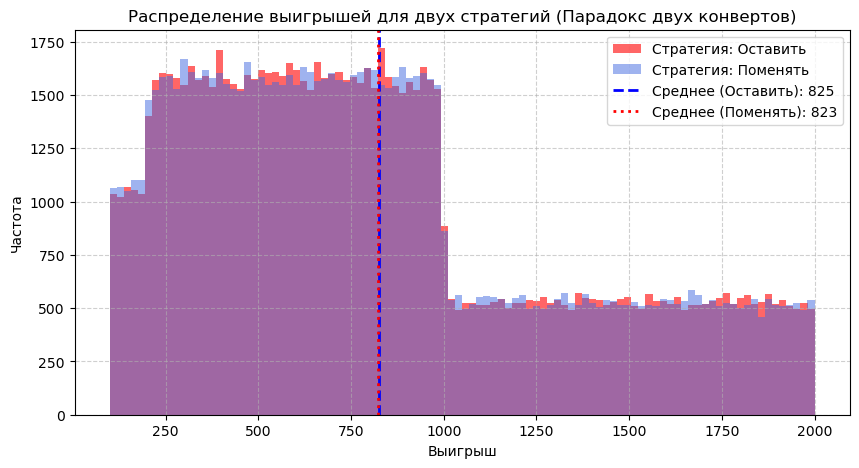

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))

plt.hist(winnings_keep, bins=100, alpha=0.6, label='Стратегия: Оставить', color='red')
plt.hist(winnings_switch, bins=100, alpha=0.5, label='Стратегия: Поменять', color='royalblue')

plt.axvline(mean_keep, color='blue', linestyle='dashed', linewidth=2, label=f'Среднее (Оставить): {mean_keep:.0f}')
plt.axvline(mean_switch, color='red', linestyle='dotted', linewidth=2, label=f'Среднее (Поменять): {mean_switch:.0f}')

plt.title('Распределение выигрышей для двух стратегий (Парадокс двух конвертов)')
plt.xlabel('Выигрыш')
plt.ylabel('Частота')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

**Вывод**
Моделирование подтверждает, что математическое ожидание выигрыша при обеих стратегиях абсолютно одинаково и равно $1.5A$ (где $A$ — среднее значение базовой суммы распределения).

Ошибочный вывод о выгоде обмена возникает из-за некорректного использования формулы полной вероятности: переменная $X$ (сумма, которую мы увидели) ошибочно трактуется как фиксированная константа. В действительности, $X$ — случайная величина, и вероятность того, что во втором конверте $2X$ или $X/2$, напрямую зависит от значения $X$ и априорного распределения базовых сумм.